# tp3 prompting

toujours la même tâche et le même split, mais sans entraînement : on demande directement à un llm qui parle. j'utilise un modèle open-weight en local via ollama (ministral-3 14b), comme ça pas de clé api et pas de coût par token.

il faut que ollama tourne (`ollama serve`) et que le modèle soit téléchargé (`ollama pull ministral-3:14b`).

In [1]:
import json
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ollama

from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42

In [2]:
df = pd.read_csv("data/speeches.csv")
train_df = df[df.split == "train"].reset_index(drop=True)
val_df = df[df.split == "val"].reset_index(drop=True)
test_df = df[df.split == "test"].reset_index(drop=True)
classes = sorted(df.speaker.unique())
print(len(test_df), classes)

193 ['CORIOLANUS', 'DUKE VINCENTIO', 'GLOUCESTER', 'ISABELLA', 'KING RICHARD III', 'MENENIUS', 'PETRUCHIO', 'ROMEO']


2) modèle llm

In [3]:
print([m.model for m in ollama.list().models])

MODELE = "ministral-3:14b"

t0 = time.time()
r = ollama.chat(model=MODELE, messages=[{"role": "user", "content": "In one sentence, who is Petruchio?"}],
                options={"temperature": 0, "num_predict": 60})
print(r.message.content)
print(f"{time.time() - t0:.1f}s | tokens entrée {r.prompt_eval_count}, sortie {r.eval_count}")

['ministral-3:14b', 'qwen3.6:27b']


Petruchio is a headstrong, quick-witted suitor in Shakespeare’s *The Taming of the Shrew* who famously "tames" the fiery Katherine through psychological games and marriage.
2.6s | tokens entrée 564, sortie 41


1) prompting

trois versions du prompt, de la plus simple à la plus riche :
- v1 zero-shot : juste la consigne et la liste des persos
- v2 zero-shot + contexte : on ajoute la pièce et une ligne de description pour chaque perso
- v3 few-shot : v2 + 2 exemples par perso tirés du train

dans tous les cas la réplique est mise entre balises (c'est de la donnée, pas une consigne) et la sortie est forcée en json avec un enum sur les noms, comme ça pas de parsing foireux. prompts en anglais vu que les textes sont en anglais.

In [4]:
desc = {
    "CORIOLANUS": "Coriolanus (play: Coriolanus). Proud Roman general, despises the plebeians and the tribunes.",
    "DUKE VINCENTIO": "Duke Vincentio (play: Measure for Measure). Duke of Vienna, spends most of the play disguised as a friar.",
    "GLOUCESTER": "Richard, Duke of Gloucester (plays: Henry VI part 3, Richard III before his coronation). Ambitious, scheming, ironic.",
    "ISABELLA": "Isabella (play: Measure for Measure). Novice nun pleading for her brother Claudio's life.",
    "KING RICHARD III": "King Richard III (play: Richard III, after his coronation). Same man as Gloucester, now king, paranoid and tyrannical.",
    "MENENIUS": "Menenius Agrippa (play: Coriolanus). Old witty patrician, friend of Coriolanus, talks a lot to the citizens and tribunes.",
    "PETRUCHIO": "Petruchio (play: The Taming of the Shrew). Boisterous gentleman from Verona who woos and 'tames' Katherina (Kate).",
    "ROMEO": "Romeo (play: Romeo and Juliet). Young Montague lover, romantic and impulsive.",
}

schema = {
    "type": "object",
    "properties": {"speaker": {"type": "string", "enum": classes}},
    "required": ["speaker"],
}

consigne = ("You are an expert in Shakespeare. You will be given one speech from a Shakespeare play, "
            "between <speech> tags. Identify which character says it. The answer must be one of the allowed characters. "
            'Reply only with JSON like {"speaker": "NAME"}.')

def system_prompt(version):
    if version == "v1":
        return consigne + "\n\nAllowed characters: " + ", ".join(classes)
    return consigne + "\n\nAllowed characters:\n" + "\n".join(f"- {c}: {desc[c]}" for c in classes)

def message_user(texte):
    return f"<speech>\n{texte}\n</speech>"

# exemples few-shot : 2 par perso, de longueur moyenne (trop court ça n'apprend rien au modèle)
rng = np.random.RandomState(SEED)
exemples = []
for c in classes:
    pool = train_df[(train_df.speaker == c) & train_df.n_mots.between(12, 40)]
    exemples += pool.sample(2, random_state=rng).to_dict("records")
rng.shuffle(exemples)  # mélangés, sinon le modèle voit les persos dans l'ordre alphabétique

def construire_messages(texte, version):
    msgs = [{"role": "system", "content": system_prompt(version)}]
    if version == "v3":
        for ex in exemples:
            msgs.append({"role": "user", "content": message_user(ex["text"])})
            msgs.append({"role": "assistant", "content": json.dumps({"speaker": ex["speaker"]})})
    msgs.append({"role": "user", "content": message_user(texte)})
    return msgs

for m in construire_messages(test_df.text[0], "v2"):
    print(f"[{m['role']}]\n{m['content']}\n")

[system]
You are an expert in Shakespeare. You will be given one speech from a Shakespeare play, between <speech> tags. Identify which character says it. The answer must be one of the allowed characters. Reply only with JSON like {"speaker": "NAME"}.

Allowed characters:
- CORIOLANUS: Coriolanus (play: Coriolanus). Proud Roman general, despises the plebeians and the tribunes.
- DUKE VINCENTIO: Duke Vincentio (play: Measure for Measure). Duke of Vienna, spends most of the play disguised as a friar.
- GLOUCESTER: Richard, Duke of Gloucester (plays: Henry VI part 3, Richard III before his coronation). Ambitious, scheming, ironic.
- ISABELLA: Isabella (play: Measure for Measure). Novice nun pleading for her brother Claudio's life.
- KING RICHARD III: King Richard III (play: Richard III, after his coronation). Same man as Gloucester, now king, paranoid and tyrannical.
- MENENIUS: Menenius Agrippa (play: Coriolanus). Old witty patrician, friend of Coriolanus, talks a lot to the citizens and 

In [5]:
# cache sur disque : chaque appel prend ~1s, pas envie de tout relancer à chaque fois
CACHE = "data/cache_llm.json"
cache = json.load(open(CACHE)) if os.path.exists(CACHE) else {}

def classer(texte, version, temperature=0.0, run=0):
    cle = f"{MODELE}|{version}|{temperature}|{run}|{texte}"
    if cle not in cache:
        t0 = time.time()
        r = ollama.chat(model=MODELE, messages=construire_messages(texte, version), format=schema,
                        options={"temperature": temperature, "seed": run, "num_predict": 30})
        cache[cle] = {"brut": r.message.content, "latence": time.time() - t0,
                      "tok_in": r.prompt_eval_count, "tok_out": r.eval_count}
    return cache[cle]

def parser(brut):
    try:
        s = json.loads(brut)["speaker"]
        return s if s in classes else None
    except (json.JSONDecodeError, KeyError, TypeError):
        return None

3) sortie générée

In [6]:
sorties = {}
for v in ["v1", "v2", "v3"]:
    t0 = time.time()
    rep = [classer(t, v) for t in test_df.text]
    json.dump(cache, open(CACHE, "w"))
    sorties[v] = pd.DataFrame(rep)
    sorties[v]["pred"] = sorties[v].brut.apply(parser)
    print(f"{v} : {time.time() - t0:.0f}s, sorties invalides : {sorties[v].pred.isna().sum()}")

v1 : 0s, sorties invalides : 0
v2 : 0s, sorties invalides : 0
v3 : 0s, sorties invalides : 0


In [7]:
# à quoi ressemble ce que le modèle renvoie
apercu = test_df[["speaker", "text"]].copy()
apercu["brut_v2"] = sorties["v2"].brut.str.replace(r"\s+", " ", regex=True)
apercu["pred_v3"] = sorties["v3"].pred
pd.set_option("display.max_colwidth", 90)
apercu.head(8)

,speaker,text,brut_v2,pred_v3
0,MENENIUS,"What work's, my countrymen, in hand? where go you With bats and clubs? The matter? spe...","{""speaker"": ""MENENIUS""}",MENENIUS
1,MENENIUS,"Sir, I shall tell you. With a kind of smile, Which ne'er came from the lungs, but even...","{""speaker"": ""MENENIUS""}",MENENIUS
2,MENENIUS,"Well, what then?","{""speaker"": ""PETRUCHIO""}",PETRUCHIO
3,MENENIUS,"The senators of Rome are this good belly, And you the mutinous members; for examine Th...","{""speaker"": ""MENENIUS""}",MENENIUS
4,CORIOLANUS,"The gods begin to mock me. I, that now Refused most princely gifts, am bound to beg Of...","{""speaker"": ""CORIOLANUS""}",CORIOLANUS
5,CORIOLANUS,I sometime lay here in Corioli At a poor man's house; he used me kindly: He cried to m...,"{""speaker"": ""CORIOLANUS""}",CORIOLANUS
6,MENENIUS,"Why, then you should discover a brace of unmeriting, proud, violent, testy magistrates...","{""speaker"": ""MENENIUS""}",MENENIUS
7,MENENIUS,"I am known to be a humorous patrician, and one that loves a cup of hot wine with not a...","{""speaker"": ""MENENIUS""}",MENENIUS


4) évaluation

In [8]:
# point de comparaison : le svm du tp1, entraîné sur train+val comme au tp1
svm = make_pipeline(
    ColumnTransformer([("c", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True), "low")]),
    LinearSVC(C=1, class_weight="balanced"))
full = pd.concat([train_df, val_df])
svm.fit(full, full.speaker)

preds = {"svm tp1": svm.predict(test_df)}
for v in sorties:
    preds[f"llm {v}"] = sorties[v].pred.fillna("INVALIDE").values

lignes = []
for nom, p in preds.items():
    pm, rm, fm, _ = precision_recall_fscore_support(test_df.speaker, p, labels=classes, average="macro", zero_division=0)
    l = {"modele": nom, "accuracy": accuracy_score(test_df.speaker, p), "precision_macro": pm, "rappel_macro": rm, "f1_macro": fm}
    if nom.startswith("llm"):
        s = sorties[nom.split()[1]]
        l.update(latence_moy_s=s.latence.mean(), tok_in_moy=s.tok_in.mean(), tok_out_moy=s.tok_out.mean())
    lignes.append(l)
res = pd.DataFrame(lignes).set_index("modele")
res.round(3)

,accuracy,precision_macro,rappel_macro,f1_macro,latence_moy_s,tok_in_moy,tok_out_moy
modele,,,,,,,
svm tp1,0.487,0.481,0.480,0.480,NaN,NaN,NaN
llm v1,0.435,0.441,0.467,0.403,0.886,156.699,11.145
llm v2,0.461,0.532,0.486,0.451,0.867,387.699,11.218
llm v3,0.472,0.524,0.488,0.453,0.966,1228.699,11.637


In [9]:
meilleur = res.f1_macro.drop("svm tp1").idxmax()
print(meilleur)
print(classification_report(test_df.speaker, preds[meilleur], labels=classes, zero_division=0))

llm v3
                  precision    recall  f1-score   support

      CORIOLANUS       0.39      0.86      0.54        22
  DUKE VINCENTIO       0.71      0.41      0.52        29
      GLOUCESTER       0.50      0.09      0.16        32
        ISABELLA       0.67      0.32      0.43        19
KING RICHARD III       0.28      0.35      0.31        20
        MENENIUS       0.47      0.67      0.55        24
       PETRUCHIO       0.45      0.74      0.56        23
           ROMEO       0.73      0.46      0.56        24

        accuracy                           0.47       193
       macro avg       0.52      0.49      0.45       193
    weighted avg       0.53      0.47      0.45       193



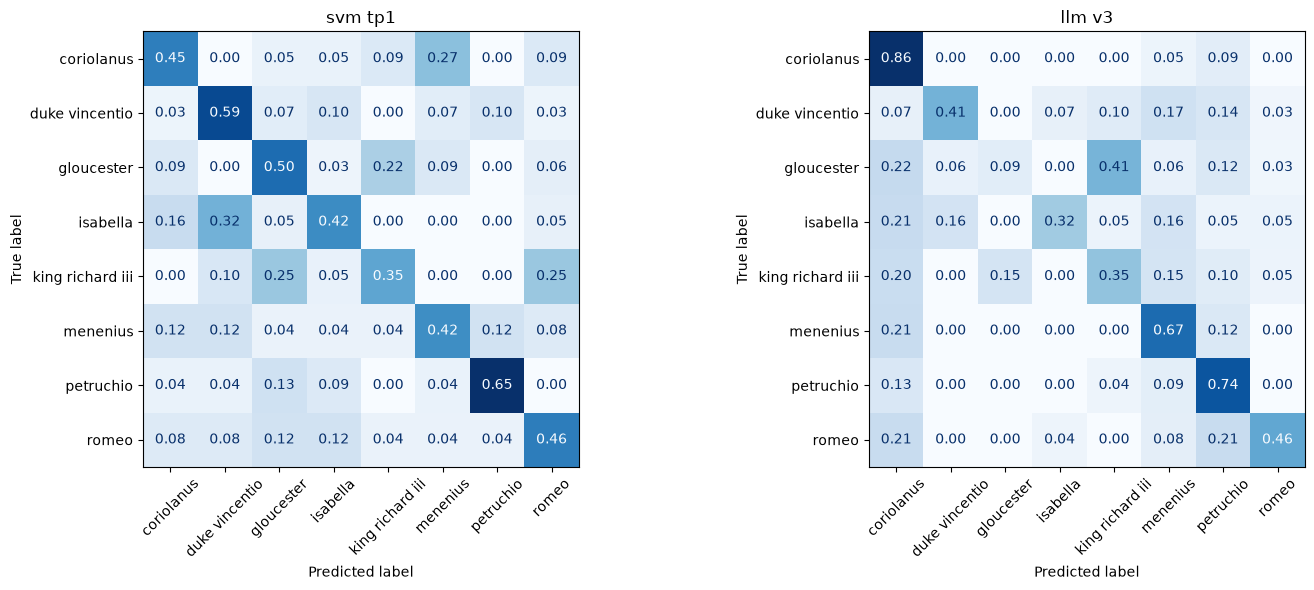

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, nom in zip(axes, ["svm tp1", meilleur]):
    cm = confusion_matrix(test_df.speaker, preds[nom], labels=classes, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=[c.lower() for c in classes]).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False, xticks_rotation=45)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

In [11]:
# le llm a t-il un perso "fourre-tout" ? distribution des prédictions vs vraie distribution
pd.DataFrame({"vrai": test_df.speaker.value_counts(),
              **{v: pd.Series(preds[f"llm {v}"]).value_counts() for v in sorties}}).fillna(0).astype(int)

,vrai,v1,v2,v3
CORIOLANUS,22,42,25,49
DUKE VINCENTIO,29,6,12,17
GLOUCESTER,32,0,5,6
ISABELLA,19,24,27,9
KING RICHARD III,20,26,28,25
MENENIUS,24,14,15,34
PETRUCHIO,23,44,51,38
ROMEO,24,37,30,15


In [12]:
# accuracy selon la longueur, comme au tp1
t = test_df.assign(ok_llm=preds[meilleur] == test_df.speaker, ok_svm=preds["svm tp1"] == test_df.speaker)
t.groupby(pd.cut(t.n_mots, [0, 5, 15, 40, 1000]), observed=True)[["ok_svm", "ok_llm"]].mean().round(2)

,ok_svm,ok_llm
n_mots,,
"(0, 5]",0.32,0.28
"(5, 15]",0.42,0.34
"(15, 40]",0.62,0.62
"(40, 1000]",0.57,0.65


effet de la température : je relance v3 trois fois avec température 1 sur 60 répliques et je regarde si les réponses changent d'un run à l'autre.

In [13]:
sous = test_df.sample(60, random_state=SEED)
runs = {}
for run in range(3):
    runs[run] = [parser(classer(x, "v3", temperature=1.0, run=run)["brut"]) for x in sous.text]
json.dump(cache, open(CACHE, "w"))

idx_sous = sous.index
base = sorties["v3"].pred[idx_sous].values
print("accuracy temp 0 :", round(accuracy_score(sous.speaker, base), 3))
for run, p in runs.items():
    print(f"run {run} temp 1 : accuracy {accuracy_score(sous.speaker, p):.3f}")
r = np.array(list(runs.values()))
print("répliques où les 3 runs sont d'accord :", round((r == r[0]).all(0).mean(), 2))

accuracy temp 0 : 0.433
run 0 temp 1 : accuracy 0.467
run 1 temp 1 : accuracy 0.450
run 2 temp 1 : accuracy 0.433
répliques où les 3 runs sont d'accord : 0.72


pour finir un petit test de génération : on demande au llm d'écrire une nouvelle réplique dans le style de chaque perso, et on regarde si le svm du tp1 reconnaît le bon perso. c'est une façon (imparfaite) d'évaluer une sortie générée sans annotation humaine.

In [14]:
def generer(perso, i):
    cle = f"{MODELE}|gen|{perso}|{i}"
    if cle not in cache:
        msgs = [{"role": "system", "content": "You write in the style of Shakespeare. Output only the speech, no name, no stage directions, no quotes."},
                {"role": "user", "content": f"Write a new speech of 2 to 4 lines for this character: {desc[perso]}"}]
        r = ollama.chat(model=MODELE, messages=msgs, options={"temperature": 0.9, "seed": i, "num_predict": 150})
        cache[cle] = {"brut": r.message.content}
    return cache[cle]["brut"].strip()

gen = pd.DataFrame([{"speaker": c, "text": generer(c, i)} for c in classes for i in range(5)])
json.dump(cache, open(CACHE, "w"))
gen["low"] = gen.text.str.lower()
gen["pred_svm"] = svm.predict(gen)
print("le svm retrouve le bon perso dans", round((gen.pred_svm == gen.speaker).mean(), 2), "des cas (hasard = 0.125)")
gen[["speaker", "pred_svm", "text"]].groupby("speaker").head(1)

le svm retrouve le bon perso dans 0.32 des cas (hasard = 0.125)


,speaker,pred_svm,text
0,CORIOLANUS,CORIOLANUS,O wretched crowd! Ye dare to breathe the same air\nAs he who hath crushed your insolen...
5,DUKE VINCENTIO,KING RICHARD III,"Hark! When the gilded sun doth steal his rays,\nAnd shadows long the trembling earth e..."
10,GLOUCESTER,KING RICHARD III,"What shadows stretch beneath this gilded throne,\nWhere every crown once wore a tyrant..."
15,ISABELLA,ROMEO,"For mercy, hear a sister’s tearful plea,\nWhose heart doth break, yet bound by holy vo..."
20,KING RICHARD III,GLOUCESTER,"O crown! A gilded serpent’s grin so wide,\nThy weight doth press upon a tyrant’s heart..."
25,MENENIUS,MENENIUS,"A knave! Yet born of noble blood, doth run\nLike honey’d mead that fools both drunk an..."
30,PETRUCHIO,ISABELLA,"A storm I’ll woo thee with, my fiery sprite!\nLet thunder kiss thee soft, let tempests..."
35,ROMEO,ROMEO,"O golden star that gilds the western sky,\nWhy dost thou fade so soon from Juliet’s ey..."


In [15]:
# vérif rapide que le modèle ne recopie pas le corpus : plus long morceau de 6 mots en commun avec le vrai texte
corpus = " ".join(open("data/tinyshakespeare.txt", encoding="utf-8").read().lower().split())
def copie_6gram(t):
    mots = t.lower().split()
    return any(" ".join(mots[i:i + 6]) in corpus for i in range(len(mots) - 5))
print("générations qui contiennent un 6-gramme du corpus :", gen.text.apply(copie_6gram).sum(), "/", len(gen))

générations qui contiennent un 6-gramme du corpus : 0 / 40


bilan : sans aucun entraînement le llm arrive presque au niveau du svm (f1 macro 0.45 contre 0.48). ajouter le contexte (pièce + description de chaque perso) aide clairement, de v1 à v2 on gagne à peu près 5 points. le few-shot (v3) n'apporte quasiment rien de plus en f1, par contre il coûte 3x plus de tokens d'entrée (~1230 contre ~390), la latence reste la même ici parce qu'ollama garde le début du prompt en cache.

le gros défaut du llm : il ne prédit presque jamais gloucester (6 fois pour 32 vrais) et met tout dans king richard iii, alors que la différence entre les deux c'est juste le moment dans la pièce. il sur-prédit aussi coriolanus et petruchio. ça ne se voit pas dans l'accuracy, il faut regarder par classe.

sur les répliques longues (plus de 40 mots) il fait mieux que le svm (0.65 vs 0.57), sûrement parce qu'il reconnaît l'intrigue voire le texte lui-même. et c'est un vrai biais d'évaluation : shakespeare est forcément dans ses données d'entraînement, donc une partie du score vient peut-être de la mémorisation et pas du style.

température 1 : l'accuracy bouge peu mais 28% des réponses changent d'un run à l'autre, donc pour de la classif on reste à température 0. pour la génération, les répliques inventées sont attribuées au bon perso par le svm 32% du temps (hasard 12.5%) et aucune ne recopie le corpus. le style est un peu là mais ça reste du shakespeare assez générique (6 générations sur 40 parlent de "gilded" quelque chose...).